In [1]:
import sys
import os
# 将 src 文件夹加入路径，确保笔记本可以导入项目代码。
sys.path.append(os.path.abspath("../src"))

import matplotlib.pyplot as plt
import numpy as np
from inr4d.data.acdc import load_acdc_patient
from inr4d.data.dataset import CoordinateDataset

print("Успешно импортировано!")

Успешно импортировано!


In [2]:
# 请把路径设置为数据集中的患者目录。
# 这里使用与默认配置一致的 patient001。
data_path = "../data/acdc/patient051"

volume = load_acdc_patient(data_path)
data = volume.data

print(f"Shape [H, W, D, T]: {data.shape}")
print(f"Voxel spacing [sx, sy, sz] mm: {volume.spacing}")
print(f"Number of frames: {data.shape[3]}")
print(f"Intensity range: {data.min()} .. {data.max()}")

Shape [H, W, D, T]: (224, 256, 10, 30)
Voxel spacing [sx, sy, sz] mm: (np.float32(1.64062), np.float32(1.64062), np.float32(10.0))
Number of frames: 30
Intensity range: 0.0 .. 255.0


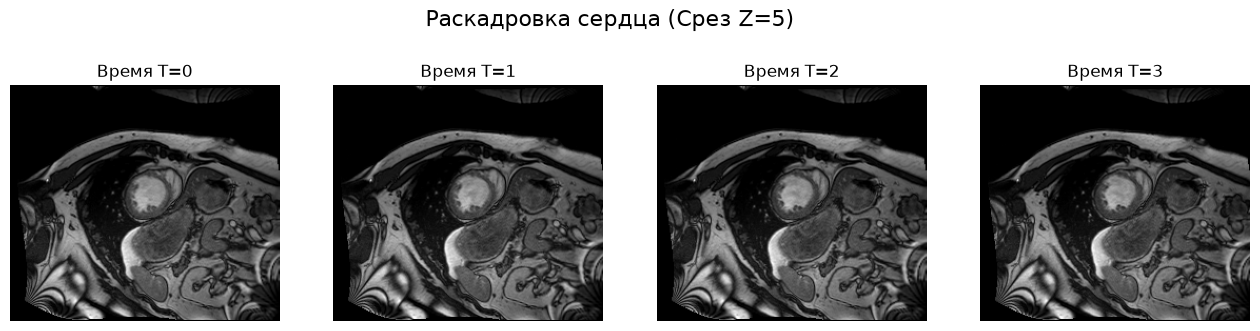

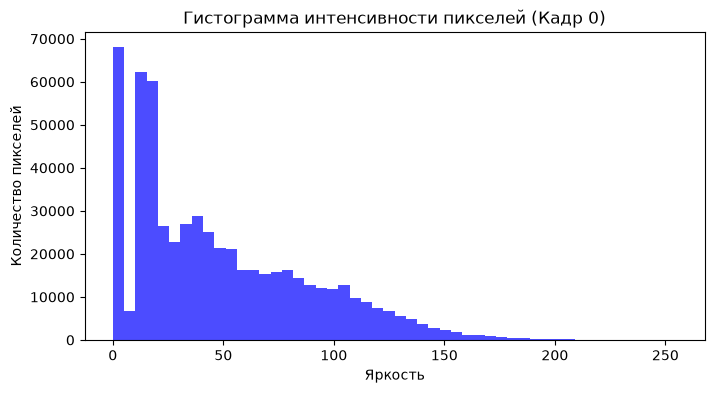

In [3]:
# 查看切片并生成逐帧拼图。
time_frame = 0  # Смотрим на первый момент времени
z_slice = data.shape[2] // 2  # Берем срез ровно посередине по оси Z

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle(f'Раскадровка сердца (Срез Z={z_slice})', fontsize=16)

# Рисуем первые 4 кадра во времени
for t in range(4):
    if t < data.shape[3]:
        axes[t].imshow(data[:, :, z_slice, t], cmap='gray')
        axes[t].set_title(f'Время T={t}')
        axes[t].axis('off')
        
plt.show()

# Рисуем гистограмму яркости
plt.figure(figsize=(8, 4))
plt.hist(data[..., 0].flatten(), bins=50, color='blue', alpha=0.7)
plt.title("Гистограмма интенсивности пикселей (Кадр 0)")
plt.xlabel("Яркость")
plt.ylabel("Количество пикселей")
plt.show()